# Dataset overview

In [1]:
from pathlib import Path
import os

# Project paths
PROJECT_DIR = Path.cwd().parent

DATASET_DIR = PROJECT_DIR / "dataset"
IMAGE_DIR = DATASET_DIR / "images"
ANNOTATION_DIR = DATASET_DIR / "annotations"

TRAIN_DIR = IMAGE_DIR / "train"
VAL_DIR = IMAGE_DIR / "val"

TRAIN_JSON = ANNOTATION_DIR / "bdd100k_labels_images_train.json"
VAL_JSON = ANNOTATION_DIR / "bdd100k_labels_images_val.json"

# Image extensions
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

# Count images recursively
def count_images(folder):
    return sum(
        1 for path in folder.rglob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )

train_count = count_images(TRAIN_DIR)
val_count = count_images(VAL_DIR)

print("DATASET OVERVIEW")
print("-" * 40)

print(f"Training images   : {train_count:,}")
print(f"Validation images : {val_count:,}")
print(f"Total images      : {train_count + val_count:,}")

print("\nANNOTATION FILES")
print("-" * 40)

print(f"Training JSON exists   : {TRAIN_JSON.exists()}")
print(f"Validation JSON exists : {VAL_JSON.exists()}")

DATASET OVERVIEW
----------------------------------------
Training images   : 69,863
Validation images : 10,000
Total images      : 79,863

ANNOTATION FILES
----------------------------------------
Training JSON exists   : True
Validation JSON exists : True


# Inspect annotation structure

In [3]:
import ijson
import json

# Read one record without loading the entire JSON file
with open(TRAIN_JSON, "rb") as file:
    first_record = next(ijson.items(file, "item"))

print(json.dumps(first_record, indent=4, default=str))

{
    "name": "0000f77c-6257be58.jpg",
    "attributes": {
        "weather": "clear",
        "scene": "city street",
        "timeofday": "daytime"
    },
    "timestamp": 10000,
    "labels": [
        {
            "category": "traffic light",
            "attributes": {
                "occluded": false,
                "truncated": false,
                "trafficLightColor": "green"
            },
            "manualShape": true,
            "manualAttributes": true,
            "box2d": {
                "x1": "1125.902264",
                "y1": "133.184488",
                "x2": "1156.978645",
                "y2": "210.875445"
            },
            "id": 0
        },
        {
            "category": "traffic light",
            "attributes": {
                "occluded": false,
                "truncated": false,
                "trafficLightColor": "green"
            },
            "manualShape": true,
            "manualAttributes": true,
            "box2d": {
    

In [20]:
print("TOP-LEVEL KEYS:")
print(first_record.keys())

print("\nIMAGE NAME:")
print(first_record.get("name"))

print("\nIMAGE ATTRIBUTES:")
print(first_record.get("attributes"))

print("\nNUMBER OF OBJECTS:")
print(len(first_record.get("labels", [])))

print("\nFIRST OBJECT:")
if first_record.get("labels"):
    print(json.dumps(first_record["labels"][0], indent=4,default=str))

TOP-LEVEL KEYS:
dict_keys(['name', 'attributes', 'timestamp', 'labels'])

IMAGE NAME:
0000f77c-6257be58.jpg

IMAGE ATTRIBUTES:
{'weather': 'clear', 'scene': 'city street', 'timeofday': 'daytime'}

NUMBER OF OBJECTS:
11

FIRST OBJECT:
{
    "category": "traffic light",
    "attributes": {
        "occluded": false,
        "truncated": false,
        "trafficLightColor": "green"
    },
    "manualShape": true,
    "manualAttributes": true,
    "box2d": {
        "x1": "1125.902264",
        "y1": "133.184488",
        "x2": "1156.978645",
        "y2": "210.875445"
    },
    "id": 0
}


# Object category distribution

We analyse the frequency of every object category in the
training and validation datasets.

This helps us:
- Identify available detection classes.
- Understand class imbalance.
- Decide which classes to include in our YOLO model.

In [6]:
from collections import Counter
import pandas as pd

def analyse_categories(json_path):
    category_counts = Counter()
    images_with_category = Counter()

    with open(json_path, "rb") as file:
        for record in ijson.items(file, "item"):

            image_categories = set()

            for obj in record.get("labels", []):
                category = obj.get("category")

                if category:
                    category_counts[category] += 1
                    image_categories.add(category)

            for category in image_categories:
                images_with_category[category] += 1

    return category_counts, images_with_category


train_categories, train_image_counts = analyse_categories(TRAIN_JSON)
val_categories, val_image_counts = analyse_categories(VAL_JSON)

category_df = pd.DataFrame({
    "Category": sorted(train_categories.keys()),
    "Train Instances": [
        train_categories[c] for c in sorted(train_categories)
    ],
    "Train Images": [
        train_image_counts[c] for c in sorted(train_categories)
    ]
})

category_df["Validation Instances"] = [
    val_categories[c] for c in category_df["Category"]
]

category_df["Validation Images"] = [
    val_image_counts[c] for c in category_df["Category"]
]

category_df

,Category,Train Instances,Train Images,Validation Instances,Validation Images
0,bike,7210,4343,1007,578
1,bus,11672,8993,1597,1242
2,car,713211,69072,102506,9879
3,drivable area,125723,66806,17981,9546
4,lane,528643,66533,75730,9526
5,motor,3002,2284,452,334
6,person,91349,22076,13262,3220
7,rider,4517,3586,649,515
8,traffic light,186117,39237,26885,5653
9,traffic sign,239686,57154,34908,8221


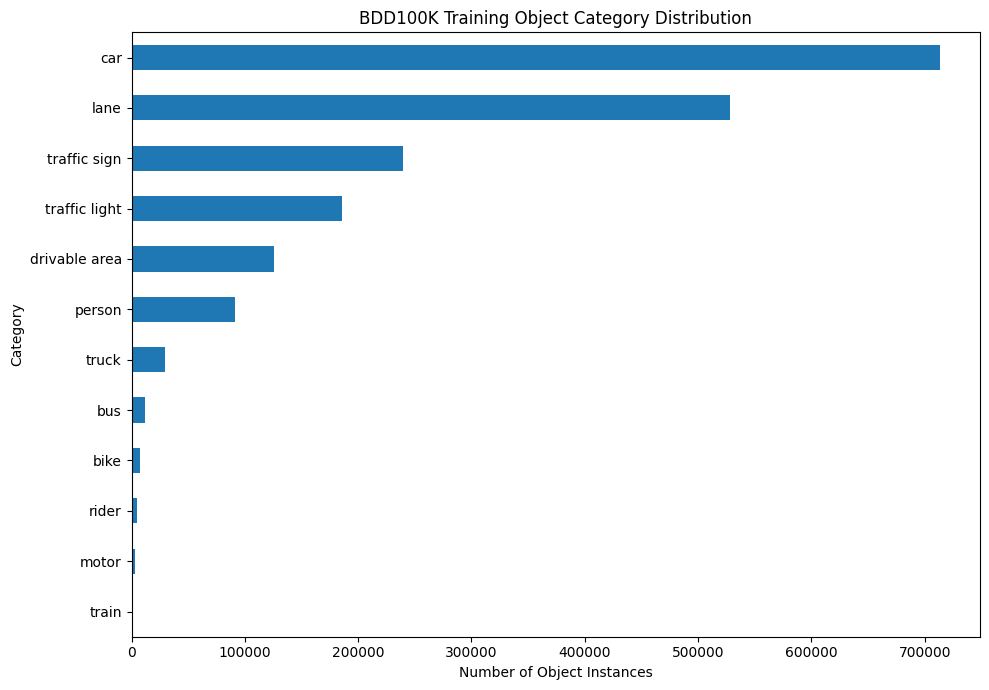

In [7]:
import matplotlib.pyplot as plt

category_df.sort_values(
    "Train Instances",
    ascending=True
).plot(
    x="Category",
    y="Train Instances",
    kind="barh",
    figsize=(10, 7),
    legend=False
)

plt.title("BDD100K Training Object Category Distribution")
plt.xlabel("Number of Object Instances")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# Weather, scene and time-of-day analysis

We analyse:
- Weather: Clear, rainy, snowy, etc.
- Scene: City street, highway, residential, etc.
- Time of day: Daytime, dawn/dusk, nighttime.

This helps us understand the diversity of driving conditions
represented in the dataset.

In [8]:
environment_counts = {
    "weather": Counter(),
    "scene": Counter(),
    "timeofday": Counter()
}

with open(TRAIN_JSON, "rb") as file:
    for record in ijson.items(file, "item"):

        attributes = record.get("attributes", {})

        for key in environment_counts:
            value = attributes.get(key)

            if value is not None:
                environment_counts[key][value] += 1


for attribute, counts in environment_counts.items():

    print(f"\n{attribute.upper()} DISTRIBUTION")
    print("-" * 40)

    for category, count in counts.most_common():
        print(f"{category:<20} {count:>8,}")


WEATHER DISTRIBUTION
----------------------------------------
clear                  37,344
overcast                8,770
undefined               8,119
snowy                   5,549
rainy                   5,070
partly cloudy           4,881
foggy                     130

SCENE DISTRIBUTION
----------------------------------------
city street            43,516
highway                17,379
residential             8,074
parking lot               377
undefined                 361
tunnel                    129
gas stations               27

TIMEOFDAY DISTRIBUTION
----------------------------------------
daytime                36,728
night                  27,971
dawn/dusk               5,027
undefined                 137


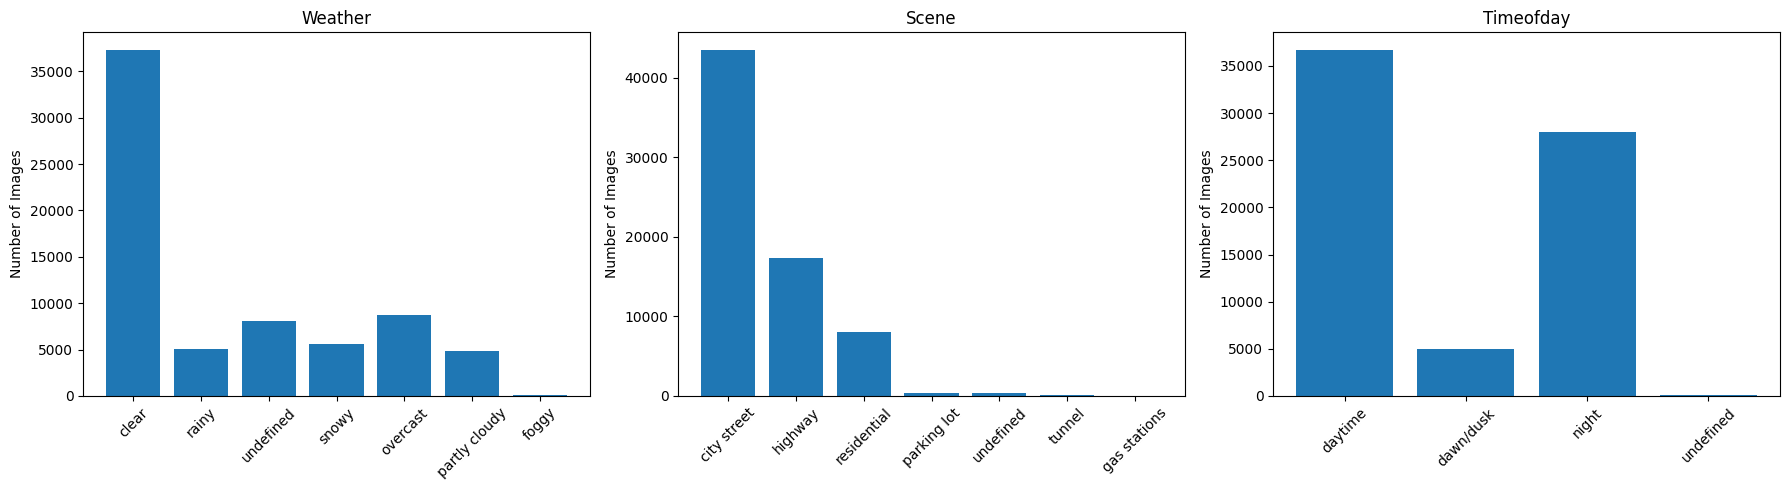

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (attribute, counts) in zip(
    axes,
    environment_counts.items()
):
    labels = list(counts.keys())
    values = list(counts.values())

    ax.bar(labels, values)
    ax.set_title(attribute.capitalize())
    ax.set_ylabel("Number of Images")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

#  Bounding Box Analysis

Bounding boxes identify the location and size of objects
within an image.

We analyse:
- Bounding-box width and height.
- Bounding-box area.
- Relative object size.
- Invalid bounding-box coordinates.

This helps us understand the spatial characteristics
of road objects.

In [10]:
import numpy as np

bbox_data = []

invalid_boxes = 0
missing_boxes = 0

with open(TRAIN_JSON, "rb") as file:
    for record in ijson.items(file, "item"):

        for obj in record.get("labels", []):

            box = obj.get("box2d")

            if not box:
                missing_boxes += 1
                continue

            x1 = box.get("x1")
            y1 = box.get("y1")
            x2 = box.get("x2")
            y2 = box.get("y2")

            if None in (x1, y1, x2, y2):
                missing_boxes += 1
                continue

            width = x2 - x1
            height = y2 - y1

            if width <= 0 or height <= 0:
                invalid_boxes += 1
                continue

            bbox_data.append({
                "category": obj.get("category"),
                "width": width,
                "height": height,
                "area": width * height
            })

bbox_df = pd.DataFrame(bbox_data)

print("Bounding Box Analysis")
print("-" * 40)
print(f"Valid boxes   : {len(bbox_df):,}")
print(f"Missing boxes : {missing_boxes:,}")
print(f"Invalid boxes : {invalid_boxes:,}")

bbox_df.describe()

Bounding Box Analysis
----------------------------------------
Valid boxes   : 1,286,871
Missing boxes : 654,366
Invalid boxes : 0


,category,width,height,area
count,1286871,1286871,1286871,1286871
unique,10,127795,113931,650042
top,car,13.499991,12.477540,205.030978312590
freq,713211,3288,3428,329


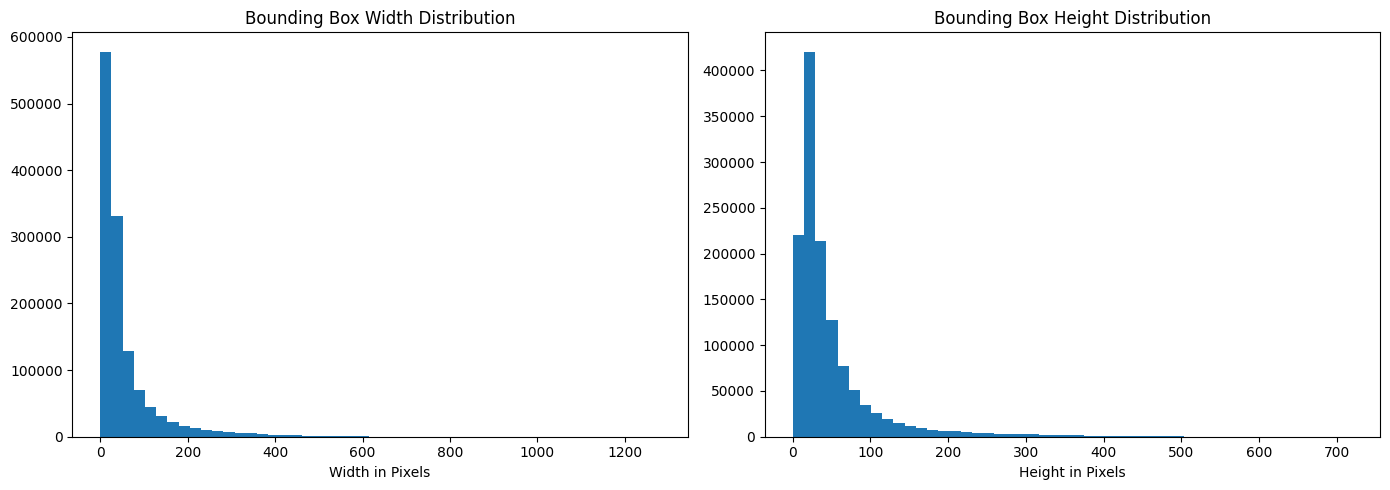

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(bbox_df["width"], bins=50)
axes[0].set_title("Bounding Box Width Distribution")
axes[0].set_xlabel("Width in Pixels")

axes[1].hist(bbox_df["height"], bins=50)
axes[1].set_title("Bounding Box Height Distribution")
axes[1].set_xlabel("Height in Pixels")

plt.tight_layout()
plt.show()

#  Annotation Visualization

We randomly select images from the training dataset,
retrieve their annotations, and draw bounding boxes.

This provides a visual understanding of the dataset's
ground-truth labels.

Indexed images: 69,863
Eligible annotated images: 69,863
Selected images: 5

Processing: 54d1b591-9c82cd06.jpg
Image dimensions: (1280, 720)
Bounding boxes drawn: 13


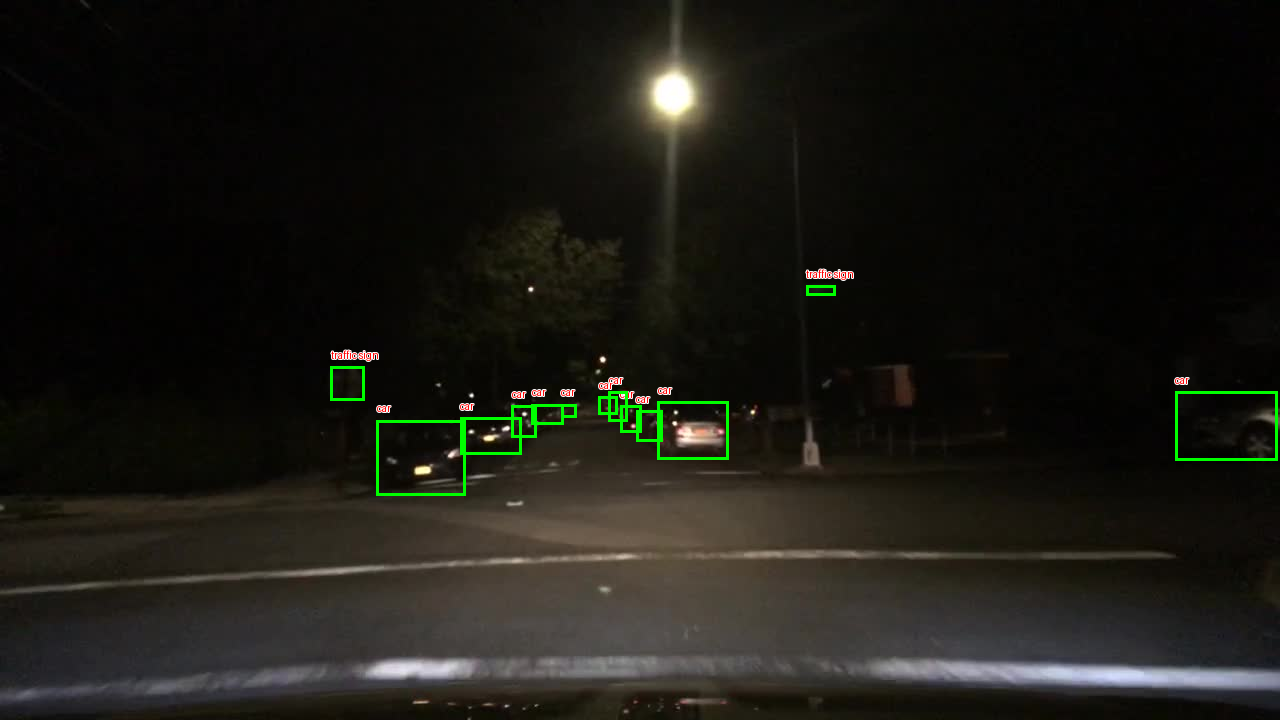


Processing: 02b7b9ee-60bfd818.jpg
Image dimensions: (1280, 720)
Bounding boxes drawn: 25


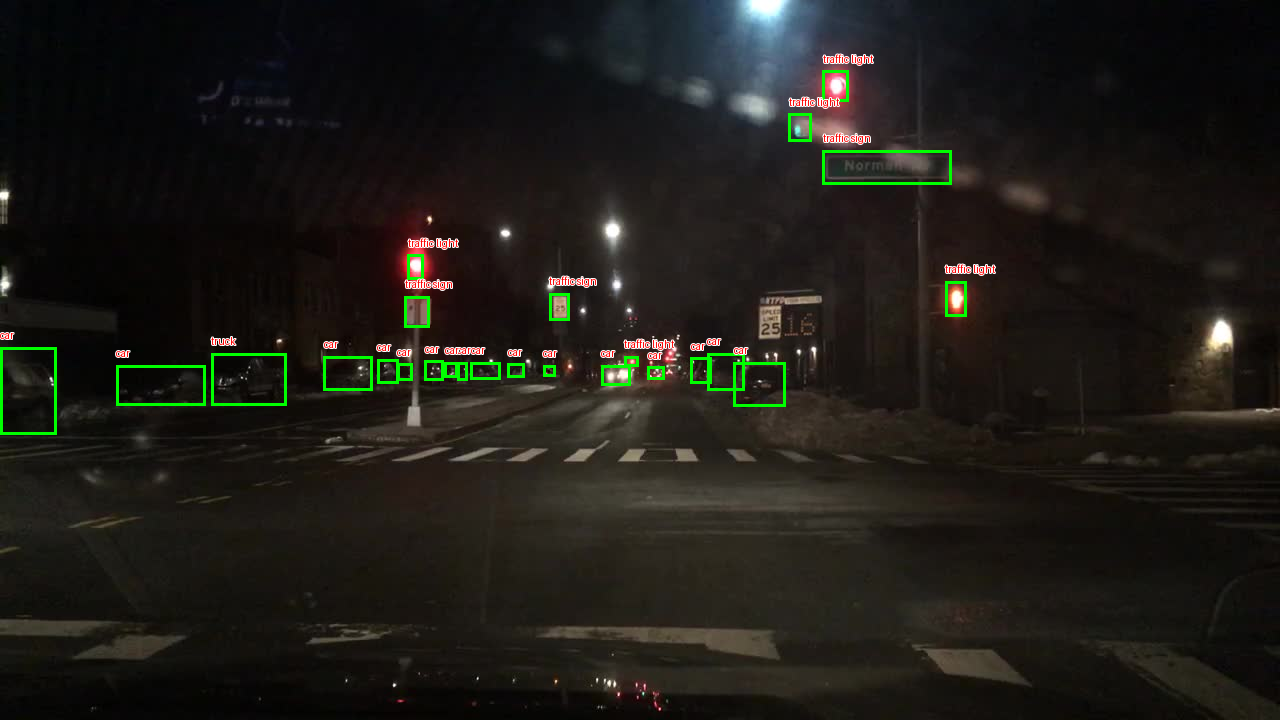


Processing: 5f532f82-c639d848.jpg
Image dimensions: (1280, 720)
Bounding boxes drawn: 8


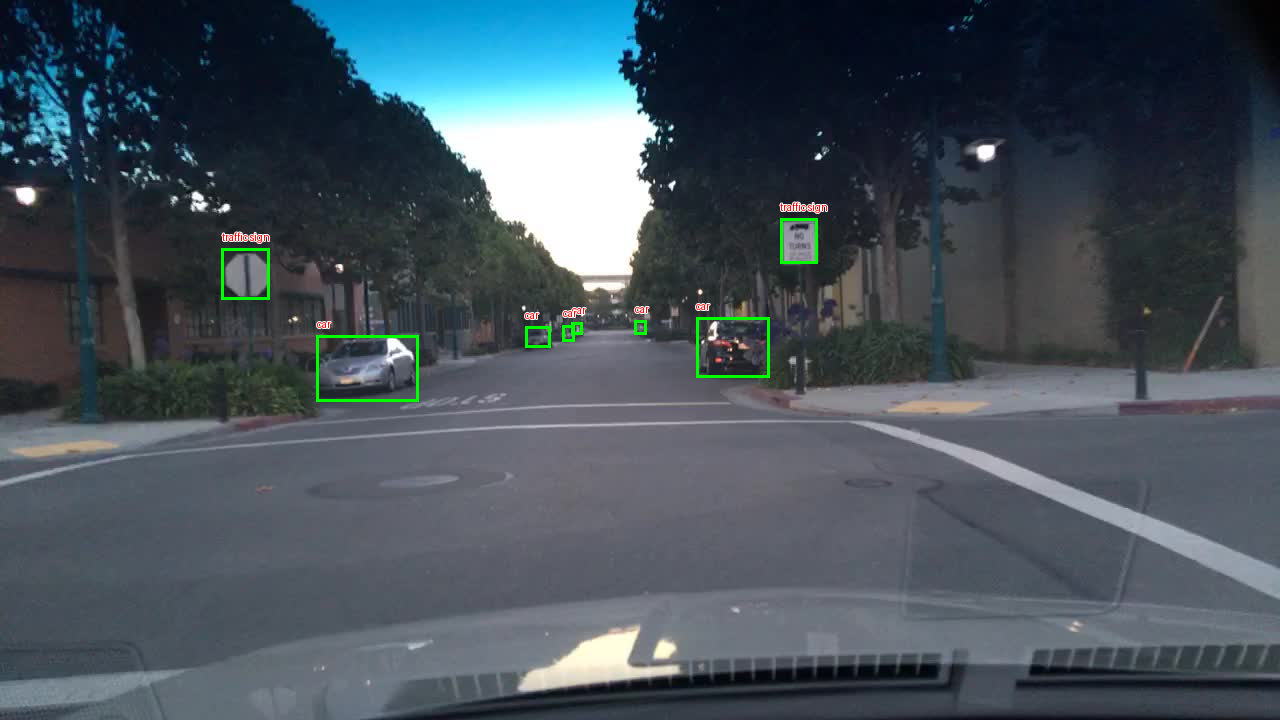


Processing: 81a87eb1-3bcbbe95.jpg
Image dimensions: (1280, 720)
Bounding boxes drawn: 5


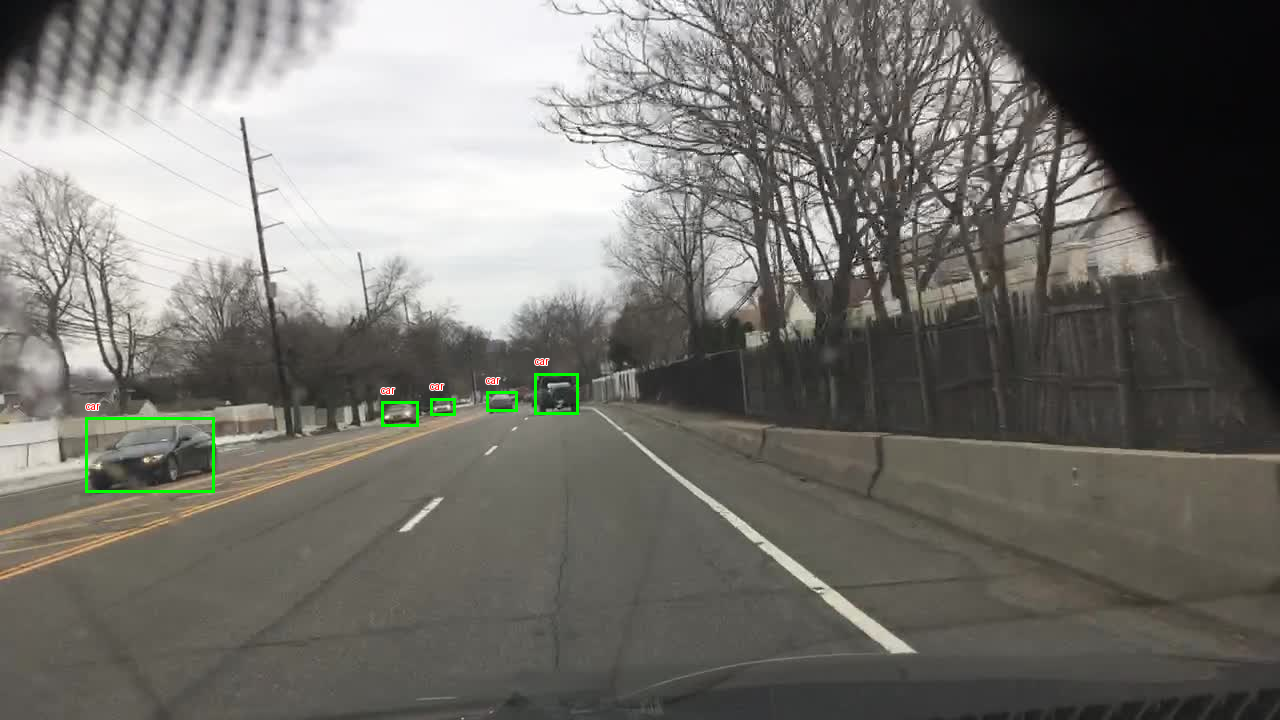


Processing: 164e47d0-9ac1e252.jpg
Image dimensions: (1280, 720)
Bounding boxes drawn: 30


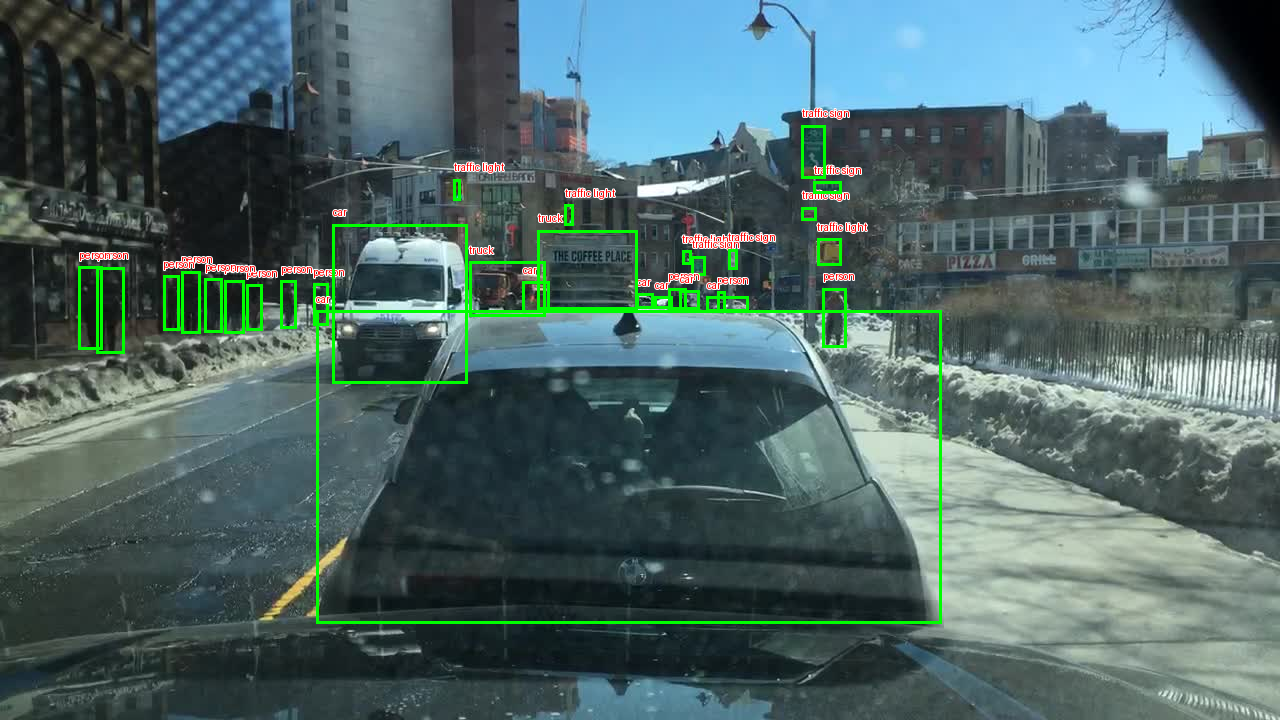

In [14]:

import random
import ijson
from PIL import Image, ImageDraw
from IPython.display import display

# --------------------------------------------------
# 1. Build image lookup
# --------------------------------------------------

image_lookup = {
    path.name: path
    for path in TRAIN_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
}

print(f"Indexed images: {len(image_lookup):,}")

assert len(image_lookup) == 69863, (
    f"Expected 69,863 images, found {len(image_lookup)}"
)

# --------------------------------------------------
# 2. Select 5 random annotated images
#    Reservoir sampling avoids loading the JSON
#    completely into RAM.
# --------------------------------------------------

samples = []

with open(TRAIN_JSON, "rb") as file:

    for record in ijson.items(file, "item"):

        if any(obj.get("box2d") for obj in record.get("labels", [])):

            if len(samples) < 5:
                samples.append(record)

            else:
                index = random.randrange(
                    sum(1 for _ in []) + 1
                )  # placeholder removed below

# --------------------------------------------------
# 3. Select samples correctly using reservoir sampling
# --------------------------------------------------

samples = []
eligible_count = 0

with open(TRAIN_JSON, "rb") as file:

    for record in ijson.items(file, "item"):

        if not any(obj.get("box2d") for obj in record.get("labels", [])):
            continue

        eligible_count += 1

        if len(samples) < 5:
            samples.append(record)

        else:
            index = random.randrange(eligible_count)

            if index < 5:
                samples[index] = record

print(f"Eligible annotated images: {eligible_count:,}")
print(f"Selected images: {len(samples)}")

# --------------------------------------------------
# 4. Draw bounding boxes using PIL
# --------------------------------------------------

for record in samples:

    filename = record["name"]
    image_path = image_lookup.get(filename)

    print(f"\nProcessing: {filename}")

    if image_path is None:
        print("ERROR: Image not found in image lookup.")
        continue

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    draw = ImageDraw.Draw(image)

    box_count = 0

    for obj in record.get("labels", []):

        box = obj.get("box2d")

        if not box:
            continue

        x1 = float(box["x1"])
        y1 = float(box["y1"])
        x2 = float(box["x2"])
        y2 = float(box["y2"])

        category = obj.get("category", "unknown")

        draw.rectangle(
            (x1, y1, x2, y2),
            outline="lime",
            width=3
        )

        draw.text(
            (x1, max(0, y1 - 18)),
            category,
            fill="red",
            stroke_width=1,
            stroke_fill="white"
        )

        box_count += 1

    print(f"Image dimensions: {image.size}")
    print(f"Bounding boxes drawn: {box_count}")

    # Display image directly
    display(image)
